# 05 — Stance detection on FEVER + offline evidence demo (MSE2)

**Fake News & Misinformation Detector** · MSE2 criteria *Model Training* / *Result Analysis* (master doc §13.3, §10.2).

1. Build the **3,000 balanced FEVER dev pairs** (1k SUPPORTS / 1k REFUTES / 1k NEI) from our `fever_subset` val split,
   with the gold sentence **text** from `copenlu/fever_gold_evidence` (our raw FEVER files only hold evidence pointers).
2. Run `cross-encoder/nli-deberta-v3-small` on CPU (premise = evidence, hypothesis = claim) — pre-trained, not fine-tuned.
3. Accuracy / macro-F1 / confusion matrix vs. the O4 target (≥ 85 %), plus the no-page-title ablation.
4. Error examples, then the offline FAISS index and one `/analyze`-style pipeline call in `MODE=offline`.

All code: `src/stance/{nli,fever_eval}.py`, `src/evidence/offline_index.py`, `src/api/pipeline.py`.

In [1]:
import sys, time, json, warnings
from pathlib import Path
import pandas as pd
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import torch; torch.set_num_threads(4)
from src.stance import fever_eval as F, nli
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 180)
T0 = time.time()

## 1. Pairs (gold sentence text joined on the FEVER claim id)

In [2]:
F.download_gold()
pairs, info = F.build_pairs()
print(info); print(pairs["label"].value_counts().to_dict())
pairs.groupby("label").head(2)[["label", "claim", "premise"]]

{'subset_rows': 3000, 'with_gold_text': 2985, 'topped_up': 15}
{'SUPPORTS': 1000, 'NEUTRAL': 1000, 'REFUTES': 1000}


,label,claim,premise
0,SUPPORTS,"John S. McCain Jr. studied in Annapolis, Maryland.","John S. McCain Jr.: McCain grew up in Washington, D.C., and graduated from the U.S. Naval Academy in 1931,..."
1,NEUTRAL,Penélope Cruz has modeled in America's Next Top Model.,"Britain's Next Top Model: As part of the Top Model franchise, it is based on the American television serie..."
2,NEUTRAL,Edison Machine Works was barely set up to produce dynamos.,"Edison Machine Works: The Edison Machine Works was a manufacturing company set up to produce dynamos, larg..."
4,REFUTES,Estonia does not border the Baltic Sea.,"Estonia: It is bordered to the north by the Gulf of Finland, to the west by the Baltic Sea, to the south b..."
6,REFUTES,West Ham United F.C. was not originally called Thames Ironworks.,West Ham United F.C.: The club was founded in 1895 as Thames Ironworks and reformed in 1900 as West Ham Un...
12,SUPPORTS,Papua comprised all of Indonesian New Guinea and it was cultured.,Papua (province): It was formerly called Irian Jaya (before that West Irian or Irian Barat) and comprised ...


## 2. NLI stance on CPU (label order read from the checkpoint's `id2label`)

In [3]:
print(nli.model().model.config.id2label)
res = F.evaluate(pairs)
plain = F.evaluate(pairs, col="premise_plain")
res["plain"] = {k: plain[k] for k in ("accuracy", "macro_f1", "cm")}
print(f"accuracy {res['accuracy']:.4f} | macro-F1 {res['macro_f1']:.4f} | {res['per_pair_ms']:.0f} ms/pair")
print(f"no-title ablation: accuracy {plain['accuracy']:.4f} | macro-F1 {plain['macro_f1']:.4f}")
print("O4 target (>= 0.85):", "met" if res["accuracy"] >= F.O4_TARGET else "NOT met")
pd.DataFrame(res["report"]).T.round(4)

{0: 'contradiction', 1: 'entailment', 2: 'neutral'}


accuracy 0.7267 | macro-F1 0.7121 | 53 ms/pair
no-title ablation: accuracy 0.6337 | macro-F1 0.6282
O4 target (>= 0.85): NOT met


,precision,recall,f1-score,support
SUPPORTS,0.8488,0.8870,0.8675,1000.0000
REFUTES,0.6190,0.8710,0.7237,1000.0000
NEUTRAL,0.7701,0.4220,0.5452,1000.0000
accuracy,0.7267,0.7267,0.7267,0.7267
macro avg,0.7460,0.7267,0.7121,3000.0000
weighted avg,0.7460,0.7267,0.7121,3000.0000


## 3. Confusion matrix (rows = gold, columns = predicted)

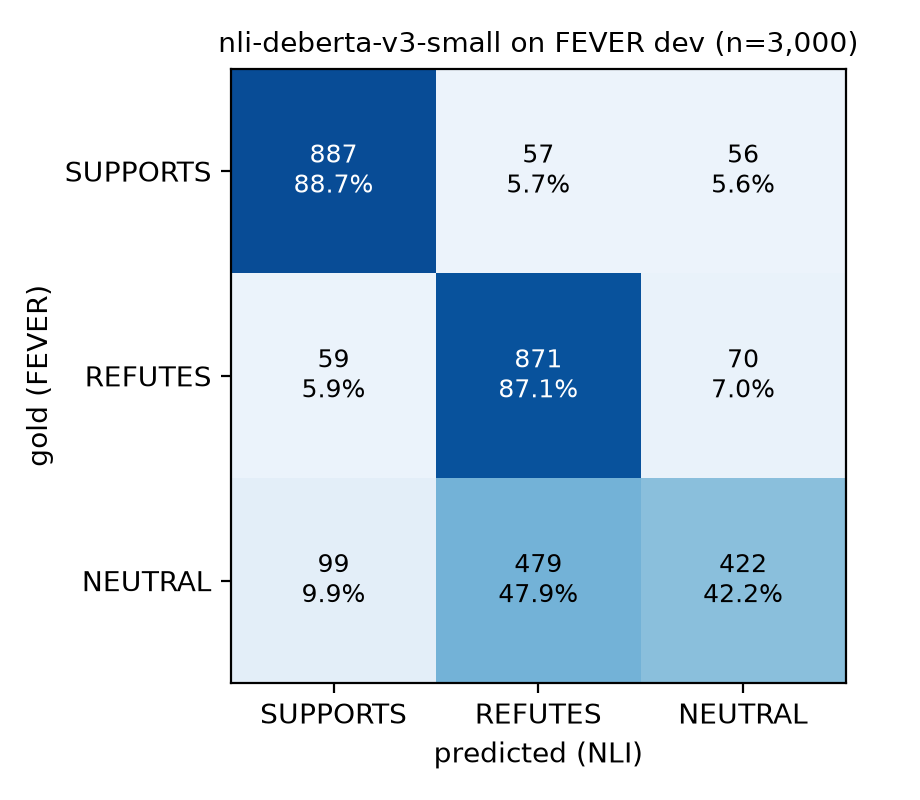

In [4]:
from IPython.display import Image
F.save_all(res, info, len(pairs))   # writes docs/results/stance_fever.md, the figure and train_logs/stance_fever.json
Image(str(F.OUT_FIG))

## 4. Where it fails

A few gold-vs-predicted disagreements per gold class. The dominant cell is **gold NEI → predicted REFUTES**: the
retrieved NEI sentence is about the same entity, and the model often reads "a different fact about X" as a
contradiction. Smaller cells: SUPPORTS claims that need world knowledge or multi-hop evidence (e.g. "studied in
Annapolis" vs. "graduated from the U.S. Naval Academy") predicted NEUTRAL.

In [5]:
pairs["pred"] = res["pred"]
err = pairs[pairs.pred != pairs.label]
print(f"{len(err)} errors"); print(pd.crosstab(err.label, err.pred))
err.groupby("label").head(3)[["label", "pred", "claim", "premise"]]

820 errors
pred      NEUTRAL  REFUTES  SUPPORTS
label                               
NEUTRAL         0      479        99
REFUTES        70        0        59
SUPPORTS       56       57         0


,label,pred,claim,premise
2,NEUTRAL,REFUTES,Edison Machine Works was barely set up to produce dynamos.,"Edison Machine Works: The Edison Machine Works was a manufacturing company set up to produce dynamos, larg..."
6,REFUTES,SUPPORTS,West Ham United F.C. was not originally called Thames Ironworks.,West Ham United F.C.: The club was founded in 1895 as Thames Ironworks and reformed in 1900 as West Ham Un...
7,NEUTRAL,REFUTES,Bret Easton Ellis barely wrote the screenplay for a 2013 film.,"Bret Easton Ellis: Less Than Zero was rapidly adapted for screen, leading to the release of a starkly diff..."
9,NEUTRAL,REFUTES,Hebe was the cupbearer for hikers of Mount Olympus.,"Hebe (mythology): Hebe ([ˈhiːbi] Ἥβη) in ancient Greek religion, is the goddess of youth (Roman equivalent..."
12,SUPPORTS,NEUTRAL,Papua comprised all of Indonesian New Guinea and it was cultured.,Papua (province): It was formerly called Irian Jaya (before that West Irian or Irian Barat) and comprised ...
35,REFUTES,SUPPORTS,Manchester United has had multiple home stadiums.,"Manchester United F.C.: Nicknamed "" the Red Devils "", the club was founded as Newton Heath LYR Football Cl..."
53,REFUTES,NEUTRAL,Blue Jasmine has an Australian actress in it.,Blue Jasmine: Blue Jasmine is a 2013 American black comedy-drama film written and directed by Woody Allen.
56,SUPPORTS,REFUTES,Spider-Man 2 was released in the 2000s.,Spider-Man 2: Spider-Man 2 is a 2004 American superhero film directed by Sam Raimi and written by Alvin Sa...
60,SUPPORTS,REFUTES,Woodrow Wilson lived.,Woodrow Wilson: Wilson's victory in the 1912 presidential election made him the first Southerner elected t...


## 5. Offline FAISS index (LIAR + FakeNewsNet PolitiFact, MiniLM, IndexFlatIP)

In [6]:
from src.evidence import offline_index as OI
print(json.loads((OI.INDEX_DIR / "build_info.json").read_text()))
t = time.time(); hits = OI.query("Says the unemployment rate doubled under Barack Obama", k=5)
print(f"query {1000 * (time.time() - t):.0f} ms")
pd.DataFrame(hits)[["cosine", "record_id", "dataset", "rating", "text"]]

{'vectors': 13892, 'dim': 384, 'model': 'sentence-transformers/all-MiniLM-L6-v2', 'index': 'IndexFlatIP (normalised)', 'by_dataset': {'liar': 12836, 'fnn_politifact': 1056}, 'faiss_mb': 20.35, 'seconds': 83.6}


query 5125 ms


,cosine,record_id,dataset,rating,text
0,0.7423,liar_5806,liar,half-true,In the Obama economy ... the youth unemployment rate is double the unemployment rate for all Americans.
1,0.6951,liar_5307,liar,false,"Since ObamaCare and the stimulus passed, the unemployment rate in the U.S. has increased."
2,0.6860,liar_6850,liar,false,Says President Obama has doubled the deficit.
3,0.6485,liar_2040,liar,barely-true,"Says that President Obama said if Congress passed the economic stimulus bill, we would have unemployment a..."
4,0.6456,liar_10858,liar,pants-fire,"During Obamas first five years as president, black unemployment increased 42 percent. During Reagans presi..."


## 6. One end-to-end call in MODE=offline (claims → offline evidence → stance → temporal → fusion)

Same function the API's `POST /analyze` calls. Evidence decides; `p_fake` only adjusts confidence / breaks the R8 tie.

In [7]:
from src.api import pipeline as P
for text in ["Says the unemployment rate doubled under Barack Obama.",
             "The bakery on Maple Street in Springfield ran out of croissants at 9 am last Tuesday."]:
    out = P.analyze(text=text, input_type="headline", mode="offline", k=5)
    print(f"\n{text}\n -> {out['verdict']} ({out['rule_fired']}, confidence {out['confidence']}) | {out['reason']}")
    print("    classifier:", out["classifier"])
    for e in out["claims"][0]["evidence"]:
        print(f"    [{e['stance']:<8} p={e['p']:.2f} cos={e['cosine']:.2f}] {e['record_id']} ({e['rating']}): {e['snippet'][:90]}")
print(f"\nnotebook runtime: {time.time() - T0:.0f} s")


Says the unemployment rate doubled under Barack Obama.
 -> UNVERIFIABLE (R1, confidence 0.8) | No reliable evidence for or against the main claim was found. This does not mean the claim is false.
    classifier: {'p_fake': 0.6049, 'label': 'fake', 'model': 'tfidf_lr_welfake_v0'}
    [NEUTRAL  p=0.97 cos=0.75] liar_5806 (half-true): In the Obama economy ... the youth unemployment rate is double the unemployment rate for a
    [NEUTRAL  p=1.00 cos=0.70] liar_5307 (false): Since ObamaCare and the stimulus passed, the unemployment rate in the U.S. has increased.
    [NEUTRAL  p=0.07 cos=0.70] liar_6850 (false): Says President Obama has doubled the deficit.
    [NEUTRAL  p=0.76 cos=0.65] liar_6118 (false): Says that under President Obama, theres been a substantial increase in federal government 
    [NEUTRAL  p=0.87 cos=0.64] liar_12877 (mostly-true): Says that under the Obama administration, the debt has nearly doubled.

The bakery on Maple Street in Springfield ran out of croissants at 9